# 1-11 목표주가·투자의견 — 증권사 눈높이와 상승여력 (신규)

**질문 예시:** "SK하이닉스 증권사 목표가 지금 얼마야? 최근에 내렸어?", "요즘 목표주가 올라간 종목 뭐야?"

CHECK 데이터에는 목표주가·투자의견이 없어서 원본 시나리오들은 "전망치 리비전"으로 대신했습니다.
DeepSearch에는 **증권사별 목표주가와 투자의견이 날짜별로** 있어서 직접 볼 수 있습니다.

| 단계 | DeepSearch |
|---|---|
| 종목 하나의 목표가·의견 이력 | `SearchTargetPrices(종목, date_from, date_to)` — 증권사·애널리스트·목표가·의견·당시 주가 |
| 시장 전체 목표가 변화 | `GetTargetPriceConsensusChange(relative_to, duration)` — **한 번 호출로 300여 종목** |
| 현재가 | 전 종목 시세(`GetStockPrices`) |

투자의견 코드: 1~2 매도·비중축소(부정), 3 중립, 4~5 매수(긍정).

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/1_fundamentals/11_target_price_opinion.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
STOCK = "KRX:000660"      # SK하이닉스
WINDOW_DAYS = 90          # 이 기간 안에 낸 목표가만 컨센서스에 씀
print(PRICE_NOTICE)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


## 1. 한 종목의 목표가 컨센서스와 상승여력
증권사별로 **최근 90일 안에 낸 가장 최신 목표가**만 남겨 평균을 냅니다(같은 증권사가 여러 번 내면 마지막 것만).

In [4]:
asof = pd.Timestamp(ASOF)
tp = ds_df(f"SearchTargetPrices({STOCK}, date_from={(asof - pd.DateOffset(years=1)).date()}, date_to={ASOF})")
NAME = tp["entity_name"].iloc[0]
OPINION = {1: "매도", 2: "비중축소", 3: "중립", 4: "매수", 5: "적극매수"}
px = stock_prices(STOCK, (asof - pd.DateOffset(years=1)).date(), ASOF, columns=["close"]).set_index("date")["close"]
close = px.iloc[-1]

recent = tp[tp["date"] > asof - pd.Timedelta(days=WINDOW_DAYS)].sort_values("date").groupby("inst_code").tail(1)
cons = recent["target_price"].mean()
print(f"{NAME} 종가 {close:,.0f}원 ({px.index[-1].date()})")
print(f"목표가 컨센서스 {cons:,.0f}원 — 증권사 {len(recent)}곳, 범위 {recent['target_price'].min():,.0f} ~ {recent['target_price'].max():,.0f}원")
print(f"상승여력 {cons / close - 1:+.1%}")
print("투자의견:", recent["opinion_code"].map(OPINION).value_counts().to_dict())
recent.assign(의견=recent["opinion_code"].map(OPINION), 당시주가=recent["current_price"],
              목표가괴리=(recent["target_price"] / recent["current_price"] - 1).map("{:+.0%}".format))[
    ["date", "name_ko", "의견", "target_price", "당시주가", "목표가괴리"]].rename(columns={"name_ko": "증권사", "target_price": "목표가"})

SK하이닉스 종가 1,158,000원 (2026-11-24)
목표가 컨센서스 3,175,000원 — 증권사 6곳, 범위 2,300,000 ~ 4,000,000원
상승여력 +174.2%
투자의견: {'매수': 6}


,date,증권사,의견,목표가,당시주가,목표가괴리
20,2026-09-28,대신증권,매수,3200000,1862000,+72%
22,2026-10-12,메리츠증권,매수,3200000,1681000,+90%
23,2026-10-29,IBK투자증권,매수,3200000,1487000,+115%
24,2026-10-29,SK증권,매수,4000000,1487000,+169%
25,2026-10-29,한화투자증권,매수,3150000,1487000,+112%
26,2026-11-04,아이엠증권,매수,2300000,1398000,+65%


## 2. 목표가 이력과 주가
점 하나가 증권사 리포트 하나입니다. 선은 날짜마다 다시 계산한 90일 컨센서스입니다.

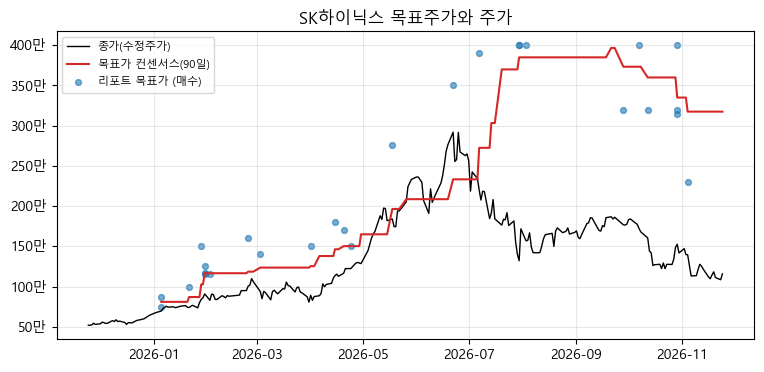

In [5]:
def cons_at(t):
    d = tp[(tp["date"] <= t) & (tp["date"] > t - pd.Timedelta(days=WINDOW_DAYS))]
    return d.sort_values("date").groupby("inst_code").tail(1)["target_price"].mean()

line = pd.Series({t: cons_at(t) for t in px.index})
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(px.index, px.values, label="종가(수정주가)", color="black", lw=1)
ax.plot(line.index, line.values, label="목표가 컨센서스(90일)", color="tab:red")
for code, g in tp.groupby("opinion_code"):
    ax.scatter(g["date"], g["target_price"], s=18, alpha=.6, label=f"리포트 목표가 ({OPINION.get(code, code)})")
ax.set_title(f"{NAME} 목표주가와 주가"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e4:,.0f}만"))

## 3. 증권사별 목표가 변경
같은 증권사가 목표가를 바꾼 기록만 모았습니다. 하향이 이어지면 눈높이가 내려가는 중입니다.

In [6]:
ch = tp.sort_values("date").copy()
ch["이전 목표가"] = ch.groupby("inst_code")["target_price"].shift()
ch = ch[ch["이전 목표가"].notna() & (ch["target_price"] != ch["이전 목표가"])]
ch["변경률"] = (ch["target_price"] / ch["이전 목표가"] - 1).map("{:+.1%}".format)
ch[["date", "name_ko", "이전 목표가", "target_price", "변경률"]].rename(
    columns={"name_ko": "증권사", "target_price": "새 목표가"}).tail(10)

,date,증권사,이전 목표가,새 목표가,변경률
10,2026-04-01,아이엠증권,1410000.0,1500000,+6.4%
14,2026-05-18,아이엠증권,1500000.0,2760000,+84.0%
15,2026-06-22,아이엠증권,2760000.0,3500000,+26.8%
16,2026-07-07,대신증권,1250000.0,3900000,+212.0%
17,2026-07-30,IBK투자증권,1800000.0,4000000,+122.2%
18,2026-07-30,SK증권,1600000.0,4000000,+150.0%
20,2026-09-28,대신증권,3900000.0,3200000,-17.9%
22,2026-10-12,메리츠증권,1700000.0,3200000,+88.2%
23,2026-10-29,IBK투자증권,4000000.0,3200000,-20.0%
26,2026-11-04,아이엠증권,3500000.0,2300000,-34.3%


## 4. 시장 전체: 최근 1개월 목표가 상향·하향 종목
`GetTargetPriceConsensusChange(relative_to=1, duration=3)`은 종목마다
- `mean_after`: **지금** 기준 최근 3개월 안 증권사별 최신 목표가 평균
- `mean_before`: **1개월 전** 기준 같은 평균
을 돌려줍니다(SK하이닉스로 직접 계산해 같은 값인지 확인함). **날짜 인자가 없어 항상 호출하는 날 기준**입니다.

In [7]:
chg = ds_df("GetTargetPriceConsensusChange(relative_to=1, duration=3)")
snap = all_stocks(ASOF)
m = chg.merge(snap[["symbol", "market", "close", "market_cap"]], on="symbol", how="inner")
m = m[(m["count_before"] >= 2) & (m["count_after"] >= 2)].copy()
m["목표가 변화"] = m["mean_after"] / m["mean_before"] - 1
m["상승여력"] = m["mean_after"] / m["close"] - 1
print(f"전체 {len(chg)}종목 중 앞뒤 모두 증권사 2곳 이상: {len(m)}종목 | 상향 {int((m['목표가 변화'] > 0).sum())} · 하향 {int((m['목표가 변화'] < 0).sum())} · 유지 {int((m['목표가 변화'] == 0).sum())}")

def view(df):
    out = df[["entity_name", "market", "mean_before", "mean_after", "목표가 변화", "count_after", "close", "상승여력", "market_cap"]].copy()
    out["목표가 변화"] = out["목표가 변화"].map("{:+.1%}".format)
    out["상승여력"] = out["상승여력"].map("{:+.0%}".format)
    out["market_cap"] = out["market_cap"].map(krw)
    for c in ("mean_before", "mean_after"):
        out[c] = out[c].round(-1).map("{:,.0f}".format)
    return out.rename(columns={"entity_name": "종목", "mean_before": "1개월 전", "mean_after": "현재", "count_after": "증권사", "close": "종가", "market_cap": "시가총액"})

print("■ 목표가 상향 상위")
display(view(m.sort_values("목표가 변화", ascending=False).head(15)))
print("■ 목표가 하향 상위")
display(view(m.sort_values("목표가 변화").head(10)))

전체 260종목 중 앞뒤 모두 증권사 2곳 이상: 144종목 | 상향 23 · 하향 107 · 유지 14
■ 목표가 상향 상위


,종목,market,1개월 전,현재,목표가 변화,증권사,종가,상승여력,시가총액
211,에코프로비엠,KOSDAQ,"107,500","135,000",+25.6%,2,88400,+53%,9.5조
213,펌텍코리아,KOSDAQ,"79,000","98,500",+24.7%,4,76600,+29%,"9,498억"
204,레이언스,KOSDAQ,"8,400","9,500",+13.1%,2,7120,+33%,"1,145억"
188,NHN,KOSPI,"83,500","93,000",+11.4%,3,51200,+82%,1.7조
89,LG유플러스,KOSPI,"18,670","19,750",+5.8%,6,14960,+32%,6.3조
126,셀트리온,KOSPI,"280,000","296,000",+5.7%,5,209000,+42%,48.5조
205,LS에코에너지,KOSPI,"68,750","72,670",+5.7%,3,37000,+96%,1.1조
70,SK텔레콤,KOSPI,"114,330","120,140",+5.1%,5,67200,+79%,14.4조
255,HD현대마린솔루션,KOSPI,"320,000","334,000",+4.4%,2,187300,+78%,8.4조
114,LG화학,KOSPI,"322,330","336,170",+4.3%,6,213500,+57%,15.1조


■ 목표가 하향 상위


,종목,market,1개월 전,현재,목표가 변화,증권사,종가,상승여력,시가총액
199,클래시스,KOSDAQ,"59,000","32,000",-45.8%,2,21600,+48%,1.4조
25,신세계,KOSPI,"685,000","431,670",-37.0%,6,269000,+60%,2.5조
133,LIG디펜스앤에어로스페이스,KOSPI,"1,136,000","728,570",-35.9%,7,366000,+99%,8.1조
2,두산,KOSPI,"2,490,000","1,715,000",-31.1%,2,620000,+177%,8.8조
153,SK오션플랜트,KOSPI,"25,000","17,670",-29.3%,3,9600,+84%,"5,998억"
92,두산에너빌리티,KOSPI,"130,000","92,250",-29.0%,4,42850,+115%,27.4조
216,실리콘투,KOSDAQ,"59,000","42,250",-28.4%,4,25800,+64%,1.7조
127,현대백화점,KOSPI,"176,670","126,670",-28.3%,3,91400,+39%,2.0조
107,한화오션,KOSPI,"134,290","97,330",-27.5%,6,43200,+125%,13.2조
50,HD한국조선해양,KOSPI,"586,000","427,670",-27.0%,3,225000,+90%,15.9조


## 5. 상승여력이 큰 대형주
시가총액 5조 이상에서 목표가 컨센서스 대비 상승여력 순입니다. 목표가가 최근 하향 중인지 같이 봅니다.

In [8]:
big = m[m["market_cap"] >= 5e12].sort_values("상승여력", ascending=False)
view(big.head(15))

,종목,market,1개월 전,현재,목표가 변화,증권사,종가,상승여력,시가총액
56,LG이노텍,KOSPI,"992,000","920,000",-7.3%,3,284500,+223%,6.7조
120,현대로템,KOSPI,"167,500","167,500",+0.0%,6,60200,+178%,6.6조
2,두산,KOSPI,"2,490,000","1,715,000",-31.1%,2,620000,+177%,8.8조
5,SK하이닉스,KOSPI,"3,600,000","3,175,000",-11.8%,6,1158000,+174%,818.5조
37,LS,KOSPI,"585,000","460,500",-21.3%,4,172300,+167%,5.4조
35,삼성전자,KOSPI,"552,000","502,860",-8.9%,7,189400,+166%,1107.3조
237,HD현대중공업,KOSPI,"804,400","626,620",-22.1%,8,250500,+150%,26.3조
47,삼성전기,KOSPI,"2,070,000","2,000,000",-3.4%,5,858000,+133%,64.1조
52,LS ELECTRIC,KOSPI,"275,830","275,830",+0.0%,6,122000,+126%,18.3조
107,한화오션,KOSPI,"134,290","97,330",-27.5%,6,43200,+125%,13.2조


## 결과 읽는 법과 한계
- **상승여력** = 목표가 컨센서스 ÷ 현재가 − 1. 증권사 목표가는 대체로 낙관적이라 절대 수준보다 **변화 방향**이 더 쓸모 있습니다.
- 주가가 급락한 직후에는 목표가가 따라 내려오기 전이라 상승여력이 크게 부풀려 보입니다. 2026-11 기준 대형주 상승여력이 +100%를 넘는 것은 10~11월 급락(예: LG이노텍 57.2만→28.5만 원)을 목표가가 아직 반영하지 못했기 때문입니다(분할 등 주가 기준 문제는 아님을 리포트 당시 주가로 확인).
- 투자의견은 대부분 "매수"(코드 4)라 변별력이 낮습니다. 의견 하향(4→3)이 나오면 드문 신호입니다.
- DeepSearch가 받는 증권사는 종목당 수 곳이라 시장 전체 컨센서스(20곳 이상)와 숫자가 다를 수 있습니다.
- 시장 전체 함수는 **오늘 기준만** 됩니다. 과거 시점의 상향·하향 목록이 필요하면 종목별 `SearchTargetPrices`로 1절처럼 계산해야 합니다.
- 수정주가 기준이라 분할·증자가 있었던 종목은 과거 목표가와 현재가를 그대로 비교하면 안 됩니다.